## Downloading Dependencies

In [1]:
import sys
!conda install --yes --prefix {sys.prefix} numpy
!conda install --yes --prefix {sys.prefix} matplotlib
!conda install --yes --prefix {sys.prefix} pandas
!conda install --yes --prefix {sys.prefix} tensorflow
!conda install --yes --prefix {sys.prefix} scikit-learn

Jupyter detected...
2 channel Terms of Service accepted
doneieving notices: - 
Channels:
 - defaults
Platform: linux-64
doneecting package metadata (repodata.json): | 
doneing environment: | 

# All requested packages already installed.

Jupyter detected...
2 channel Terms of Service accepted
Channels:
 - defaults
Platform: linux-64
doneecting package metadata (repodata.json): - 
doneing environment: / 

# All requested packages already installed.

Jupyter detected...
2 channel Terms of Service accepted
Channels:
 - defaults
Platform: linux-64
doneecting package metadata (repodata.json): - 
doneing environment: / 

# All requested packages already installed.

Jupyter detected...
2 channel Terms of Service accepted
Channels:
 - defaults
Platform: linux-64
doneecting package metadata (repodata.json): - 
doneing environment: / 

# All requested packages already installed.

Jupyter detected...
2 channel Terms of Service accepted
Channels:
 - defaults
Platform: linux-64
doneecting package m

## Importing Libraries

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, roc_auc_score, precision_recall_curve, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import TargetEncoder, OneHotEncoder, StandardScaler
from keras import layers, losses
from keras.datasets import fashion_mnist
from keras.models import Model
from scipy.sparse import csr_matrix

import hashlib
import json
import ast

2025-08-01 09:48:20.297229: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-08-01 09:48:20.376129: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## Anomaly Detection on BETH Dataset

In [3]:
training_dataframe = pd.read_csv('Dataset/labelled_training_data.csv')
testing_dataframe = pd.read_csv('Dataset/labelled_testing_data.csv')
validation_dataframe = pd.read_csv('Dataset/labelled_validation_data.csv')

raw_training_data = training_dataframe.values
raw_testing_data = testing_dataframe.values
raw_validation_data = validation_dataframe.values

training_dataframe.head()

,timestamp,processId,threadId,parentProcessId,userId,mountNamespace,processName,hostName,eventId,eventName,stackAddresses,argsNum,returnValue,args,sus,evil
0,1809.495787,381,7337,1,100,4026532231,close,ip-10-100-1-120,157,prctl,"[140662171848350, 11649800180280676]",5,0,"[{'name': 'option', 'type': 'int', 'value': 'P...",1,0
1,1809.495832,381,7337,1,100,4026532231,close,ip-10-100-1-120,3,close,[140662171777451],1,0,"[{'name': 'fd', 'type': 'int', 'value': 19}]",1,0
2,1809.495921,381,7337,1,100,4026532231,close,ip-10-100-1-120,1010,sched_process_exit,[],0,0,[],1,0
3,1894.139651,7347,7347,7341,0,4026531840,sh,ip-10-100-1-120,21,access,[],2,-2,"[{'name': 'pathname', 'type': 'const char*', '...",1,0
4,1894.142127,7347,7347,7341,0,4026531840,sh,ip-10-100-1-120,1005,security_file_open,"[139778263990104, 139778263906698]",4,0,"[{'name': 'pathname', 'type': 'const char*', '...",1,0


As adviced by the authors of the beth dataset's paper, we applied these transformation:

- ProcessId and ParentprocessId: 0 if it is [0,1,2] otherwise 1
- UserId: 0 if id is less than 1000 otherwise 1
- MountNameSpace: 0 if it is equal to 4026531840 otherwise 1
- ReturnValue: 0 if it is 0, 1 if it is positive and 2 if it is negative     
- Drop timestamp column since not time series related
- Drop eventName as uniquely mapped to eventId
- Encode processName, threadId and eventId using target encoding
- Drop stackAddresses
- Drop HostName
- Args column contains a list of maximum 5 dictionaries, each disctionary contains three elements ({'name': 'dev', 'type': 'dev_t', 'value': 211812353}). We created 15 new columns in each datset, and assigns each element from the dictionaries to its respective new column. After which apply target encoding.

There is no need to normalize or scale the data as the magnitude is not relevant for the numeric data with the exception of ArgsNum which i encoded using scalar.

In [4]:
# Function to split the string column into list of dictionaries and create new columns
def split_and_expand(row):
    if pd.isna(row):
        return pd.Series([None] * 15)

    dicts = ast.literal_eval(row)
    result = {'name_{}'.format(i+1): None for i in range(5)}
    result.update({'type_{}'.format(i+1): None for i in range(5)})
    result.update({'value_{}'.format(i+1): None for i in range(5)})

    for i, d in enumerate(dicts):
        if i >= 5:  # We only want to process the first 5 dictionaries
            break
        result['name_{}'.format(i+1)] = d.get('name')
        result['type_{}'.format(i+1)] = d.get('type')
        result['value_{}'.format(i+1)] = d.get('value')

    return pd.Series(result)

In [5]:
def apply_transformations(data, encoder, scaler, is_training=False):

    # Define column names
    columns = ['timestamp', 'processId', 'threadId', 'parentProcessId', 'userId', 
               'mountNamespace', 'processName', 'hostName', 'eventId', 'eventName', 
               'stackAddresses', 'argsNum', 'returnValue', 'args', 'sus', 'evil']

    # Convert to DataFrame for easier column manipulation
    df = pd.DataFrame(data, columns=columns)
    
    # Transform ProcessId
    df['processId'] = np.where(np.isin(df['processId'], [0, 1, 2]), 0, 1)
    # Transform ParentProcessId
    df['parentProcessId'] = np.where(np.isin(df['parentProcessId'], [0, 1, 2]), 0, 1)
    # Transform UserId
    df['userId'] = np.where(df['userId'] < 1000, 0, 1)
    # Transform MountNameSpace
    df['mountNamespace'] = np.where(df['mountNamespace'] == 4026531840, 0, 1)
    # Transform ReturnValue
    df['returnValue'] = np.where(df['returnValue'] == 0, 0,
                                np.where(df['returnValue'] > 0, 1, 2))
    
    # Store Args Column before dropping
    args_column = df['args'].copy()

    # Normalise Args Num
    # Reshape the 'argsNum' column to a 2D array before applying the scaler
    df['argsNum'] = scaler.fit_transform(df['argsNum'].values.reshape(-1, 1))
    
    # Drop columns by name
    cols_to_drop = ['timestamp', 'stackAddresses', 'args', 'eventName', 'hostName']
    df_filtered = df.drop(columns=cols_to_drop)
    
    # Apply split_and_expand to the stored args column
    expanded_args = args_column.apply(split_and_expand)
    
    # Join the expanded columns with the DataFrame
    df_data = df_filtered.join(expanded_args)

    categorical_cols = [col for col in df_data.columns if 'name_' in str(col) or 'type_' in str(col) or 'value_' in str(col)] + ['processName', 'threadId', 'eventId']
    for col in categorical_cols:
        # Replace NaN with 'unknown'
        df_data[col] = df_data[col].fillna('unknown')
        # Convert all values in categorical columns to strings
        df_data[col] = df_data[col].astype(str)

    # Fit the encoder on the training set (if not already fitted)
    if is_training:
        encoder.fit(df_data[categorical_cols], df_data['sus'].astype(int))
        
    # Use the existing encoder for validation/test data
    encoded_data = encoder.transform(df_data[categorical_cols])
    df_encoded = pd.DataFrame(encoded_data, columns=encoder.get_feature_names_out(categorical_cols), index=df_data.index)
    
    # Drop original categorical columns and concatenate encoded columns
    df_data = df_data.drop(columns=categorical_cols)
    df_data = pd.concat([df_data, df_encoded], axis=1)
    
    return df_data

In [6]:
c_encoder = TargetEncoder()
scaler = StandardScaler()

# Apply transformations to the datasets
transformed_training_data = apply_transformations(raw_training_data, c_encoder, scaler, True)
transformed_testing_data = apply_transformations(raw_testing_data, c_encoder, scaler)
transformed_validation_data = apply_transformations(raw_validation_data, c_encoder, scaler)

/tmp/ipykernel_4456/1419985687.py:43: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_data[col] = df_data[col].fillna('unknown')
/tmp/ipykernel_4456/1419985687.py:43: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_data[col] = df_data[col].fillna('unknown')
/tmp/ipykernel_4456/1419985687.py:43: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)

Now we can split the data and labels

In [7]:
# Get the labels by selecting the 9th column (index 8)
training_labels = transformed_training_data.iloc[:, 6]
testing_labels = transformed_testing_data.iloc[:, 6]
validation_labels = transformed_validation_data.iloc[:, 6]

# Remove the columns 8 and 9 (labels) from the features
training_data = transformed_training_data.drop(columns=[transformed_training_data.columns[6], transformed_training_data.columns[7]])
testing_data = transformed_testing_data.drop(columns=[transformed_testing_data.columns[6], transformed_testing_data.columns[7]])
validation_data = transformed_validation_data.drop(columns=[transformed_validation_data.columns[6], transformed_validation_data.columns[7]])

In [8]:
# Checking Data
pd.set_option("display.max_columns", None)
training_df = pd.DataFrame(training_data)
print(training_df.tail())
# print(training_df['sus'].unique())
# print(training_df['sus'].dtype)


        processId  parentProcessId  userId  mountNamespace   argsNum  \
763139          1                1       0               0 -1.246980   
763140          1                1       0               0 -0.501215   
763141          1                1       0               0 -1.992744   
763142          1                0       0               0 -1.992744   
763143          1                0       0               0 -1.246980   

        returnValue    name_1    name_2    name_3    name_4    name_5  \
763139            0  0.000000  0.001142  0.002022  0.002133  0.001644   
763140            0  0.000000  0.000000  0.002022  0.002133  0.001644   
763141            0  0.023907  0.001142  0.002022  0.002133  0.001644   
763142            0  0.023907  0.001142  0.002022  0.002133  0.001644   
763143            0  0.001354  0.001142  0.002022  0.002133  0.001644   

          type_1    type_2    type_3    type_4    type_5   value_1   value_2  \
763139  0.001350  0.001142  0.002022  0.002133  

In [9]:
# Convert the data type to float32 and Tensor
training_data = np.array(training_data, dtype=np.float32)
testing_data = np.array(testing_data, dtype=np.float32)
validation_data = np.array(validation_data, dtype=np.float32)

training_data = tf.constant(training_data)
testing_data = tf.constant(testing_data)
validation_data = tf.constant(validation_data)

# Float32
training_data = tf.cast(training_data, tf.float32)
testing_data = tf.cast(testing_data, tf.float32)
validation_data = tf.cast(validation_data, tf.float32)

Separate the anomalous/suspicious from the non-suspicious

In [10]:
# training_labels = training_labels.astype(bool)
# testing_labels = testing_labels.astype(bool)
# validation_labels = validation_labels.astype(bool)

# # Normal data (unsuspicious)
# normal_training_data = training_data[~training_labels]
# normal_testing_data = testing_data[~testing_labels]
# normal_validation_data = validation_data[~validation_labels]

# # Anomalous data (suspicious)
# anomalous_training_data = training_data[training_labels]
# anomalous_testing_data = testing_data[testing_labels]
# anomalous_validation_data = validation_data[validation_labels]

# Ensure training_labels, testing_labels, and validation_labels are tensors (if not already)
training_labels = tf.convert_to_tensor(training_labels.astype(bool), dtype=tf.bool)
testing_labels = tf.convert_to_tensor(testing_labels.astype(bool), dtype=tf.bool)
validation_labels = tf.convert_to_tensor(validation_labels.astype(bool), dtype=tf.bool)

# Use tf.boolean_mask to select normal/anomalous data
normal_training_data = tf.boolean_mask(training_data, ~training_labels)
anomalous_training_data = tf.boolean_mask(training_data, training_labels)

normal_testing_data = tf.boolean_mask(testing_data, ~testing_labels)
anomalous_testing_data = tf.boolean_mask(testing_data, testing_labels)

normal_validation_data = tf.boolean_mask(validation_data, ~validation_labels)
anomalous_validation_data = tf.boolean_mask(validation_data, validation_labels)


In [11]:
# Check class distribution in each dataset
print("Training set distribution:")
print(f"Normal: {len(normal_training_data)} ({len(normal_training_data)/len(training_data)*100:.1f}%)")
print(f"Anomalous: {len(anomalous_training_data)} ({len(anomalous_training_data)/len(training_data)*100:.1f}%)")

print("\nTesting set distribution:")
print(f"Normal: {len(normal_testing_data)} ({len(normal_testing_data)/len(testing_data)*100:.1f}%)")
print(f"Anomalous: {len(anomalous_testing_data)} ({len(anomalous_testing_data)/len(testing_data)*100:.1f}%)")

print("\nValidation set distribution:")
print(f"Normal: {len(normal_validation_data)} ({len(normal_validation_data)/len(validation_data)*100:.1f}%)")
print(f"Anomalous: {len(anomalous_validation_data)} ({len(anomalous_validation_data)/len(validation_data)*100:.1f}%)")

Training set distribution:
Normal: 761875 (99.8%)
Anomalous: 1269 (0.2%)

Testing set distribution:
Normal: 17508 (9.3%)
Anomalous: 171459 (90.7%)

Validation set distribution:
Normal: 188181 (99.6%)
Anomalous: 786 (0.4%)


Now with an understanding of the data and the data prepared, we can build the model

In [12]:
@tf.keras.utils.register_keras_serializable()
class AnomalyDetector(tf.keras.Model):
    def __init__(self, **kwargs):
        super(AnomalyDetector, self).__init__(**kwargs)
        self.encoder = tf.keras.Sequential([
          # layers.Dense(16, activation="relu"),
          # # Model was overfitting so add dropout layers
          # layers.Dropout(0.2),
          # layers.Dense(8, activation="relu"),
          # layers.Dropout(0.2),
          # layers.Dense(4, activation="relu")

            layers.Dense(32, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dropout(0.1),
            layers.Dense(16, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dense(10, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
        ])
    
        self.decoder = tf.keras.Sequential([

            layers.Dense(16, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dropout(0.1),
            layers.Dense(32, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dense(24)
            
          # layers.Dense(8, activation="relu"),
          # layers.Dropout(0.2),
          # layers.Dense(16, activation="relu"),
          # layers.Dropout(0.1),
          # layers.Dense(24)
        ])
      
    def call(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

    def get_config(self):
        # Return config dictionary; empty because no constructor args
        base_config = super(AnomalyDetector, self).get_config()
        return base_config

    @classmethod
    def from_config(cls, config):
        return cls(**config)


autoencoder = AnomalyDetector()

In [13]:
autoencoder.compile(optimizer='adam', loss='mae')

In [14]:
sample = tf.convert_to_tensor(normal_training_data[:1], dtype=tf.float32)
output = autoencoder(sample)
print("Sample output:", output.numpy())


Sample output: [[ 0.06001831 -0.00503629 -0.12395768  0.04363865 -0.01046217  0.11184841
  -0.08217227  0.0311371  -0.07293449 -0.00861429  0.0170975   0.04227956
   0.02616376  0.03389039 -0.06883881 -0.0206228  -0.03583229  0.11500743
   0.03604058  0.11684074 -0.03202347  0.0610711   0.04625811  0.0581211 ]]


In [15]:
# Callbacks
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6
)

In [18]:
limited_training_data = normal_training_data
limited_validation_data = validation_data

history = autoencoder.fit(limited_training_data, limited_training_data,
          epochs=20,
          batch_size=64, #Number of training samples model processes before updating its weights during training
          validation_data=(validation_data, validation_data),
          callbacks=[early_stopping, reduce_lr],
          shuffle=True)

Epoch 1/20
11905/11905 ━━━━━━━━━━━━━━━━━━━━ 10s 847us/step - loss: 0.0178 - val_loss: 0.0365 - learning_rate: 0.0010
Epoch 2/20
11905/11905 ━━━━━━━━━━━━━━━━━━━━ 10s 851us/step - loss: 0.0105 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 3/20
11905/11905 ━━━━━━━━━━━━━━━━━━━━ 10s 805us/step - loss: 0.0014 - val_loss: 0.0042 - learning_rate: 0.0010
Epoch 4/20
11905/11905 ━━━━━━━━━━━━━━━━━━━━ 10s 828us/step - loss: 0.0013 - val_loss: 0.0038 - learning_rate: 0.0010
Epoch 5/20
11905/11905 ━━━━━━━━━━━━━━━━━━━━ 10s 820us/step - loss: 0.0012 - val_loss: 0.0040 - learning_rate: 0.0010
Epoch 6/20
11905/11905 ━━━━━━━━━━━━━━━━━━━━ 9s 796us/step - loss: 0.0011 - val_loss: 0.0037 - learning_rate: 0.0010
Epoch 7/20
11905/11905 ━━━━━━━━━━━━━━━━━━━━ 10s 809us/step - loss: 0.0011 - val_loss: 0.0038 - learning_rate: 0.0010
Epoch 8/20
11905/11905 ━━━━━━━━━━━━━━━━━━━━ 9s 796us/step - loss: 0.0010 - val_loss: 0.0041 - learning_rate: 0.0010
Epoch 9/20
11905/11905 ━━━━━━━━━━━━━━━━━━━━ 10s 809us/step - loss:

To visualize the loss (or the measure of the model s predictions) during the training process

In [19]:
autoencoder.save('Models/10f_cae_model.keras')

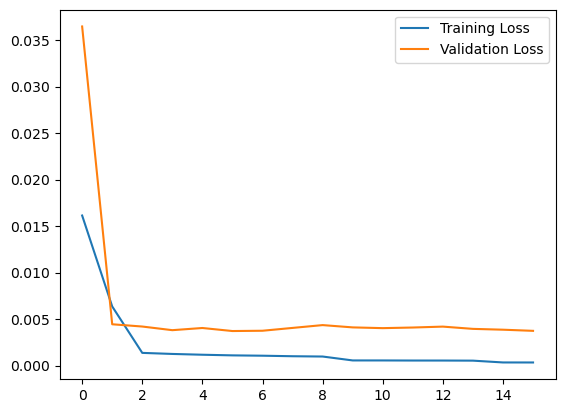

In [20]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()

Now we plot a normal instance from the training set and compare it with the same instance reconstructed by the autoencoder.


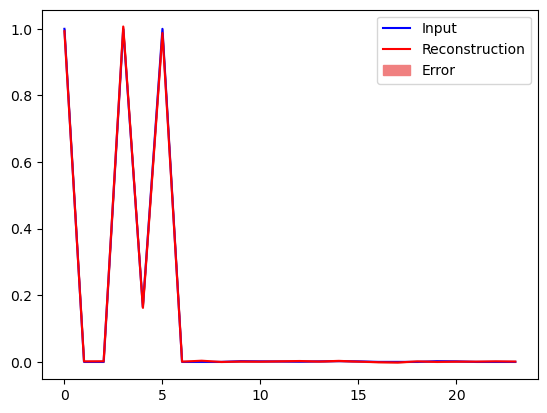

In [21]:
encoded_data = autoencoder.encoder(normal_testing_data).numpy()
decoded_normal = autoencoder.decoder(encoded_data).numpy()

plt.plot(normal_testing_data[0], 'b') # Plot in blue
plt.plot(decoded_normal[0], 'r') # Plot in red
# Fill space between the curves with light red
plt.fill_between(np.arange(24), decoded_normal[0], normal_testing_data[0], color='lightcoral')
plt.legend(labels=["Input", "Reconstruction", "Error"])
plt.show()


We repeat but this time for the anomalous example

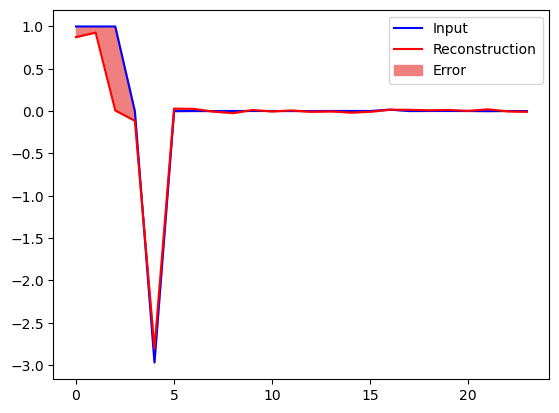

In [22]:
encoded_data = autoencoder.encoder(anomalous_testing_data).numpy()
decoded_anomalous = autoencoder.decoder(encoded_data).numpy()

plt.plot(anomalous_testing_data[0], 'b') # Plot in blue
plt.plot(decoded_anomalous[0], 'r') # Plot in red
# Fill space between the curves with light red
plt.fill_between(np.arange(24), decoded_anomalous[0], anomalous_testing_data[0], color='lightcoral')
plt.legend(labels=["Input", "Reconstruction", "Error"])
plt.show()


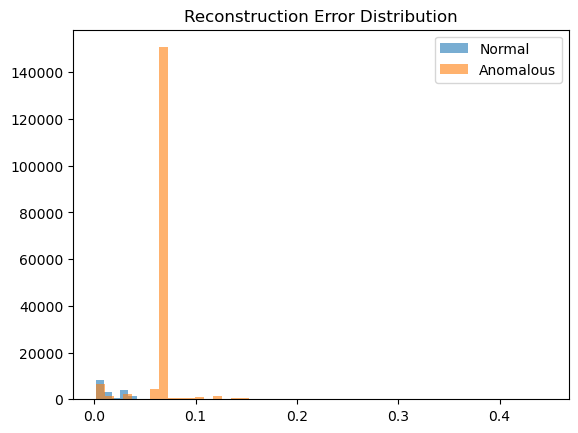

In [23]:
normal_recon_error = np.mean(np.abs(normal_testing_data - decoded_normal), axis=1)
anomalous_recon_error = np.mean(np.abs(anomalous_testing_data - decoded_anomalous), axis=1)

plt.hist(normal_recon_error, bins=50, alpha=0.6, label='Normal')
plt.hist(anomalous_recon_error, bins=50, alpha=0.6, label='Anomalous')
plt.legend()
plt.title("Reconstruction Error Distribution")
plt.show()


23809/23809 ━━━━━━━━━━━━━━━━━━━━ 10s 416us/step


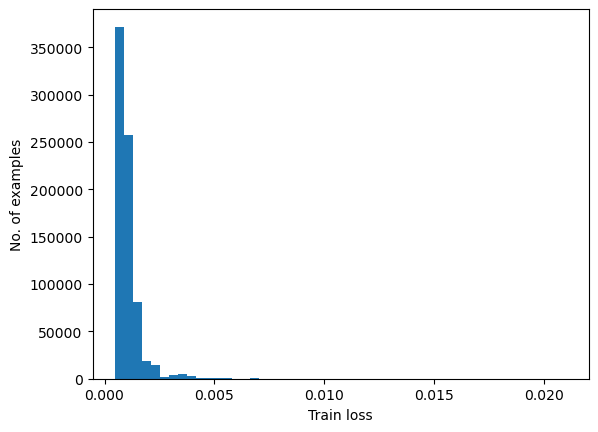

In [24]:
reconstructions = autoencoder.predict(normal_training_data)
train_loss = tf.keras.losses.mae(reconstructions, normal_training_data)

plt.hist(train_loss[None,:], bins=50)
plt.xlabel("Train loss")
plt.ylabel("No. of examples")
plt.show()

In [25]:
reconstructions = autoencoder.predict(training_data)
reconstructions_error = tf.keras.losses.mae(reconstructions, training_data)

# Get precision, recall, thresholds
# precisions, recalls, thresholds = precision_recall_curve(training_labels, reconstructions_error)

# # Find best threshold (e.g., max F1)
# f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
# best_idx = np.argmax(f1_scores)
# threshold = thresholds[best_idx]

# print("Threshold: ", threshold)


# Calculate mean and std of the reconstruction errors
mean_error = np.mean(reconstructions_error)
std_error = np.std(reconstructions_error)

# Set threshold to be mean + N * std, where N is a hyperparameter you can tune
threshold = mean_error + 2 * std_error  # For a more aggressive threshold, decrease the multiplier

print("Threshold: ", threshold)

# Make predictions based on the threshold
predictions = reconstructions_error > threshold


23849/23849 ━━━━━━━━━━━━━━━━━━━━ 10s 418us/step
Threshold:  0.021102684


If we examine the reconstruction error for the anomalous examples in the test set, you'll notice most have greater reconstruction error than the threshold. By varing the threshold, we can adjust the precision and recall of your classifier.

5359/5359 ━━━━━━━━━━━━━━━━━━━━ 2s 430us/step


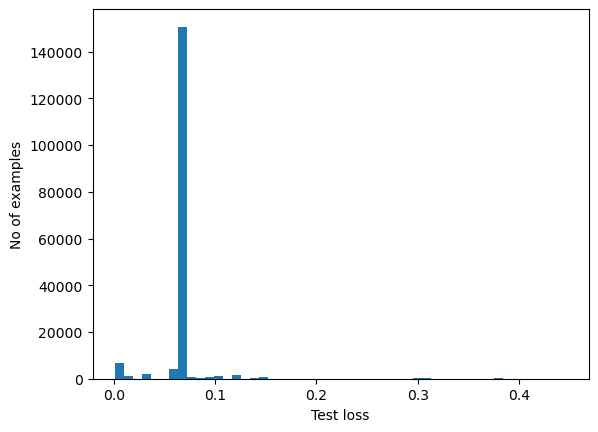

In [26]:
reconstructions = autoencoder.predict(anomalous_testing_data)
test_loss = tf.keras.losses.mae(reconstructions, anomalous_testing_data)

# Plot a histogram, we add an extra axis to the 1D test_loss array with None to become 2D
# Bins is the number of intervals for the histogram
plt.hist(test_loss[None, :], bins=50)
plt.xlabel("Test loss")
plt.ylabel("No of examples")
plt.show()

With our threshold defined, we can classify suspicious honeypot traffic as an anomaly if the reconstruction error is greater than the threshold

In [27]:
def predict(model, data, threshold):
    reconstructions = model(data)
    loss = tf.keras.losses.mae(reconstructions, data)
    # Detects if value greater than threshold then return true (for suspicious) else false (not suspicious)
    return tf.math.greater(loss, threshold)

def print_stats(predictions, labels):

    labels = labels.numpy().astype(int)
    predictions = predictions.numpy().astype(int)
    
    print("Accuracy = {}".format(accuracy_score(labels, predictions)))
    print("Precision = {}".format(precision_score(labels, predictions)))
    print("Recall = {}".format(recall_score(labels, predictions)))

In [28]:
preds = predict(autoencoder, testing_data, threshold)
print_stats(preds, testing_labels)

Accuracy = 0.9293580360592061
Precision = 0.9672170870664996
Recall = 0.9544964102205192


Therefore the current model implementation has an overall accuracy of 93.4%.
It has a false discovery rate of 1.4% and a false negative rate of 5.9%.

In [29]:
tn, fp, fn, tp = confusion_matrix(testing_labels.numpy().astype(int), preds.numpy().astype(int)).ravel()
fpr = fp / (fp + tn)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print("False Positive Rate (FPR):", fpr)

TN=11961, FP=5547, FN=7802, TP=163657
False Positive Rate (FPR): 0.316826593557231


In [30]:
# AUROC to compare with BETH Paper
reconstructions = autoencoder(testing_data)
reconstruction_errors = tf.keras.losses.mae(reconstructions, testing_data).numpy()
auroc = roc_auc_score(testing_labels, reconstruction_errors)

print("AUROC:", auroc)

AUROC: 0.9548872011761207


### AUROC Results
Compared with results from:  
*BETH Dataset: Real Cybersecurity Data for Anomaly Detection Research*    
*Table 3 
https://www.gatsby.ucl.ac.uk/~balaji/udl2021/accepted-papers/UDL2021-paper-033.pdf*

| Method                     | AUROC |
|----------------------------|--------|
| **Classical Autoencoder (Ours)** | **0.916** |
| Robust Covariance           | 0.519 |
| One-Class SVM               | 0.605 |
| IForest                     | 0.850 |
| VAE + DoSE (SVM)            | 0.698 |
        

### Classification Report

In [31]:
reconstructions = autoencoder.predict(testing_data)
reconstruction_errors = tf.keras.losses.mae(reconstructions, testing_data)

predictions = reconstruction_errors.numpy() > threshold
ground_truth = testing_labels.numpy().astype(bool)

print(classification_report(ground_truth, predictions))

5906/5906 ━━━━━━━━━━━━━━━━━━━━ 2s 389us/step
              precision    recall  f1-score   support

       False       0.61      0.68      0.64     17508
        True       0.97      0.95      0.96    171459

    accuracy                           0.93    188967
   macro avg       0.79      0.82      0.80    188967
weighted avg       0.93      0.93      0.93    188967



### Additional Testing on Validation Data

In [75]:
preds = predict(autoencoder, validation_data, threshold)
print_stats(preds, validation_labels)

Accuracy = 0.9999523726364921
Precision = 1.0
Recall = 0.9885496183206107


In [76]:
tn, fp, fn, tp = confusion_matrix(validation_labels.numpy().astype(int), preds.numpy().astype(int)).ravel()
fpr = fp / (fp + tn)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print("False Positive Rate (FPR):", fpr)

TN=188181, FP=0, FN=9, TP=777
False Positive Rate (FPR): 0.0


In [77]:
reconstructions = autoencoder.predict(validation_data)
reconstruction_errors = tf.keras.losses.mae(reconstructions, validation_data)

predictions = reconstruction_errors.numpy() > threshold
ground_truth = testing_labels.numpy().astype(bool)

print(classification_report(ground_truth, predictions))

print(threshold)

5906/5906 ━━━━━━━━━━━━━━━━━━━━ 3s 423us/step
              precision    recall  f1-score   support

       False       0.09      1.00      0.17     17508
        True       0.98      0.00      0.01    171459

    accuracy                           0.10    188967
   macro avg       0.53      0.50      0.09    188967
weighted avg       0.89      0.10      0.02    188967

0.02267337


## Summary

**Dataset Distributions**              
Training set distribution:            
Normal: 761875 (99.8%)            
Anomalous: 1269 (0.2%)             

Testing set distribution:          
Normal: 17508 (9.3%)             
Anomalous: 171459 (90.7%)           

Validation set distribution:          
Normal: 188181 (99.6%)         
Anomalous: 786 (0.4%)          

**AUROC Metric**           
Compared with results from:  
*BETH Dataset: Real Cybersecurity Data for Anomaly Detection Research*    
*Table 3 
https://www.gatsby.ucl.ac.uk/~balaji/udl2021/accepted-papers/UDL2021-paper-033.pdf*

| Method                     | AUROC |
|----------------------------|--------|
| **Classical Autoencoder (Ours)** | **0.916** |
| Robust Covariance           | 0.519 |
| One-Class SVM               | 0.605 |
| IForest                     | 0.850 |
| VAE + DoSE (SVM)            | 0.698 |       

**Model Performance on Testing Dataset (High Anomalous)**       
Accuracy = 0.9347716797112723          
Precision = 0.9863448267431129           
Recall = 0.9411404475705563                           

TN=15274, FP=2234, FN=10092, TP=161367                
False Positive Rate (FPR): 0.12759881197167008               

**Model Performance on Validation Dataset (More Realistic but Seen)**         
Accuracy = 0.9757470881159144             
Precision = 0.14520650345729771           
Recall = 0.9885496183206107                 

TN=183607, FP=4574, FN=9, TP=777               
False Positive Rate (FPR): 0.024306385873175292                     

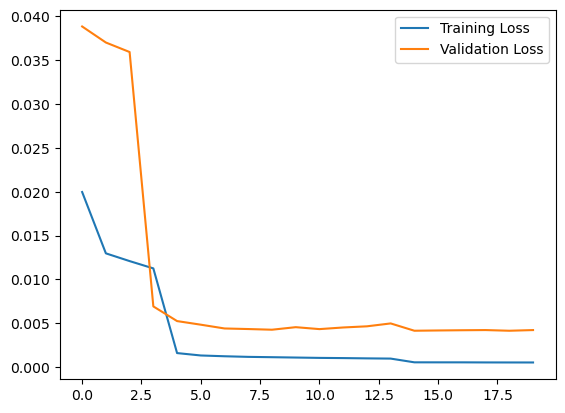

In [67]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()